# TP N° 2 - Inteligencia Artificial
## RNA MLP BP para estimacion de SOH y RUL en baterias CALCE (CS2_35)

**Especificaciones:**
- **RNA MLP BP:** red densamente conectada con Backpropagation. Se experimenta con la topologia variando capas ocultas y neuronas.
- **ConvNet 1D (alternativa):** red convolucional unidimensional que extrae caracteristicas locales de la serie temporal.
- **Datos:** CSV normalizado con atributos por ciclo de batería CS253.
- **Target:** valor continuo (SOH % o RUL en ciclos).

**Dataset:** `dataset_CS2_35_ciclos.csv` (generado por `1_preparacion_dataset_baterias.ipynb`)

**Mapeo de atributos de entrada (segun spec → nuestro dataset):**

| Atributo spec | Columna dataset | Disponible |
|---|---|:---:|
| Numero de ciclo actual | `Ciclo_k_Norm` | Si |
| Voltaje (medio de descarga) | `Voltaje_Medio_Descarga_V_Norm` | Si |
| Duracion del ciclo de carga | `Tiempo_Fase_CV_s_Norm` | Si |
| Impedancia (resistencia interna) | `Resistencia_Interna_Ohm_Norm` | Si |
| Voltaje maximo/minimo por ciclo | -- | No |
| Corriente de carga/descarga | -- | No |
| Temperatura de la celda | -- | No |

> Los atributos no disponibles (voltaje max/min, corriente, temperatura) no fueron registrados por el Arbin en este experimento o se agregaran si el dataset los contiene.

In [130]:
#@title Librerias a usar
from tensorflow import keras
from tensorflow.keras.models import Model
from tensorflow.keras.utils import plot_model
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

import tensorflow as tf
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
import math
import time
import os

from google.colab import drive
drive.mount('/content/drive')

# Semilla para reproducibilidad
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print(f"TensorFlow: {tf.__version__}")
print("Librerias cargadas")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
TensorFlow: 2.21.0
Librerias cargadas


---
## 1. Carga y preparacion de datos

- **X (entradas):** atributos normalizados [0, 1]
- **Y (target):** SOH_% o RUL_Ciclos (valor continuo, sin normalizar)
- **Split:** train (80%) / test (20%) sin mezclar (respeta el orden temporal)
- **Tipo de problema:** Estimacion (regresion), NO clasificacion

In [131]:
#@title Cargar dataset y separar datos
#@markdown ### Ruta del dataset normalizado:
PATH_DATASET = '/content/drive/MyDrive/IA 2C 2026 G12/TP 2/Datos/datos Procesados/dataset_CS2_35_ciclos.csv' #@param {type:"string"}

#@markdown ### Target a predecir:
target_seleccionado = "SOH_%" #@param ["SOH_%", "RUL_Ciclos"]

#@markdown ### Porcentaje para test:
porcentaje_test = 10 #@param {type:"number"}

# Cargar dataset
df = pd.read_csv(PATH_DATASET)
print(f"Dataset cargado: {len(df)} ciclos")
print(f"Columnas: {df.columns.tolist()}")

# Identificar columnas de entrada (terminan en _Norm)
columnas_x = [c for c in df.columns if c.endswith('_Norm')]
print(f"\nAtributos de entrada (X): {columnas_x}")
print(f"Target (Y): {target_seleccionado}")

# Separar X e Y
x_all = df[columnas_x].values.astype(np.float32)
y_all = df[target_seleccionado].values.astype(np.float32)

print(f"\nX shape: {x_all.shape}")
print(f"Y range: [{y_all.min():.2f}, {y_all.max():.2f}]")

# Split train/test sin mezclar (orden temporal)
x_train, x_test, y_train, y_test = train_test_split(
    x_all, y_all, test_size=porcentaje_test/100.0, shuffle=True
)

# Problema de estimacion (NO clasificacion)
esProblemaClasificacion = False
tipo_output_softMax = False

# (código existente...)
print(f"\nTrain: {len(x_train)} ciclos | Test: {len(x_test)} ciclos")

# Verificar que no hay solapamiento entre train y test
print(f"\nVerificacion de integridad:")
print(f"  Train: {len(x_train)} muestras")
print(f"  Test:  {len(x_test)} muestras")
print(f"  Total: {len(x_train) + len(x_test)}")
print(f"  Dataset: {len(x_all)}")
assert len(x_train) + len(x_test) == len(x_all), "Solapamiento detectado!"

print(f"\nPrimeras 5 filas:")
display(df.head())

Dataset cargado: 930 ciclos
Columnas: ['Ciclo_k_Norm', 'Voltaje_Medio_Descarga_V_Norm', 'Tiempo_Fase_CV_s_Norm', 'Resistencia_Interna_Ohm_Norm', 'SOH_%', 'RUL_Ciclos', 'Bateria_Origen']

Atributos de entrada (X): ['Ciclo_k_Norm', 'Voltaje_Medio_Descarga_V_Norm', 'Tiempo_Fase_CV_s_Norm', 'Resistencia_Interna_Ohm_Norm']
Target (Y): SOH_%

X shape: (930, 4)
Y range: [27.85, 100.00]

Train: 837 ciclos | Test: 93 ciclos

Verificacion de integridad:
  Train: 837 muestras
  Test:  93 muestras
  Total: 930
  Dataset: 930

Primeras 5 filas:


,Ciclo_k_Norm,Voltaje_Medio_Descarga_V_Norm,Tiempo_Fase_CV_s_Norm,Resistencia_Interna_Ohm_Norm,SOH_%,RUL_Ciclos,Bateria_Origen
0,0.000000,0.942528,0.613374,0.008057,100.0,576,CS2_35_8_17_10
1,0.001076,0.924711,0.595969,0.004029,100.0,575,CS2_35_8_18_10
2,0.002153,0.930940,0.590363,0.000000,100.0,574,CS2_35_8_19_10
3,0.003229,0.929886,0.589286,0.000000,100.0,573,CS2_35_8_30_10
4,0.004306,0.965044,0.594839,0.000000,100.0,572,CS2_35_8_30_10


In [132]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## 2. RNA MLP Backpropagation

Arquitectura base: red densamente conectada (Multi-Perceptron) entrenada con Backpropagation.

**Parametros configurables:**
- `capas_ocultas`: lista de neuronas por capa, separada por comas. Soporta `D` (Dropout) y `BN` (BatchNormalization).
- `funcion_activacion`: ReLU, tanh, sigmoid, etc.
- `optimizador`: Adam, SGD, RMSprop, etc.
- `learning_rate`: tasa de aprendizaje
- `epocas`: cantidad maxima de epocas
- `early stopping`: detiene si val_loss no mejora

In [133]:
#@title Establecer parametros del modelo MLP

#@markdown ### Parametros de la Red:
capas_ocultas = '64,32' #@param {type:"string"}
funcion_activacion = 'relu' #@param ['relu', 'tanh', 'sigmoid', 'linear', 'exponential']
porc_capa_DropOut = 0.0 #@param {type:"number"}

#@markdown ### Parametros del Optimizador:
opt_tipo = "Adam" #@param ["Adam", "Gradiente Decreciente", "Adadelta", "Adagrad", "Adamax", "Nadam", "RMSprop", "Momentum", "NAG"]
opt_learning_rate = 0.001 #@param {type:"number"}

# --- Funciones auxiliares (adaptadas del template) ---

def agregarCapaEntrada(num_inputs):
    return tf.keras.layers.Input(shape=(num_inputs,), name='input')

def agregarCapasLineales(eachLay, configCapasList, tipo_funcion="relu", porc_capa_DropOut=0.1):
    assert eachLay is not None, "Capa anterior no definida!"
    porc_capa_DropOut = min(max(0.0, porc_capa_DropOut), 0.9)
    auxId = 1
    for val_hid in configCapasList:
        val_hid = val_hid.strip()
        if val_hid.upper() == "D":
            eachLay = tf.keras.layers.Dropout(porc_capa_DropOut, name='drop_'+str(auxId))(eachLay)
            auxId += 1
        elif val_hid.upper() == "BN":
            eachLay = tf.keras.layers.BatchNormalization(name='bn_'+str(auxId))(eachLay)
            auxId += 1
        elif val_hid.isnumeric():
            eachLay = tf.keras.layers.Dense(int(val_hid), activation=tipo_funcion, name='hidd_'+str(auxId))(eachLay)
            auxId += 1
        else:
            print("Tipo capa", val_hid, "descartada!")
    return eachLay

def agregarCapaSalida(eachLay):
    assert eachLay is not None, "Capa anterior no definida!"
    # Estimacion: salida lineal, loss MSE, metrica RMSE
    output_Lay = tf.keras.layers.Dense(1, activation=None, name='output')(eachLay)
    metricsType = ['RootMeanSquaredError']
    lossType = 'mse'
    return output_Lay, metricsType, lossType

def definirOpt(opt_tipo, opt_learning_rate=0.001):
    opt_learning_rate = min(max(0.00001, opt_learning_rate), 10)
    if opt_tipo == "Gradiente Decreciente":
        opt = keras.optimizers.SGD(learning_rate=opt_learning_rate)
    elif opt_tipo == "Adam":
        opt = keras.optimizers.Adam(learning_rate=opt_learning_rate)
    elif opt_tipo == "Adadelta":
        opt = keras.optimizers.Adadelta(learning_rate=opt_learning_rate)
    elif opt_tipo == "Adagrad":
        opt = keras.optimizers.Adagrad(learning_rate=opt_learning_rate)
    elif opt_tipo == "Adamax":
        opt = keras.optimizers.Adamax(learning_rate=opt_learning_rate)
    elif opt_tipo == "Nadam":
        opt = keras.optimizers.Nadam(learning_rate=opt_learning_rate)
    elif opt_tipo == "RMSprop":
        opt = keras.optimizers.RMSprop(learning_rate=opt_learning_rate)
    elif opt_tipo == "Momentum":
        opt = keras.optimizers.SGD(learning_rate=opt_learning_rate, momentum=0.9, nesterov=False)
    elif opt_tipo == "NAG":
        opt = keras.optimizers.SGD(learning_rate=opt_learning_rate, momentum=0.9, nesterov=True)
    else:
        opt = keras.optimizers.Adam(learning_rate=opt_learning_rate)
    return opt

# --- Construir el modelo ---
input_Lay = agregarCapaEntrada(num_inputs=x_train.shape[1])
eachLay = input_Lay
eachLay = agregarCapasLineales(eachLay,
                               configCapasList=capas_ocultas.split(','),
                               tipo_funcion=funcion_activacion,
                               porc_capa_DropOut=porc_capa_DropOut)
output_Lay, metricsType, lossType = agregarCapaSalida(eachLay)
optModel = definirOpt(opt_tipo=opt_tipo, opt_learning_rate=opt_learning_rate)

model = Model(input_Lay, output_Lay, name='RNA_MLP_BP')
model.compile(optimizer=optModel, loss=lossType, metrics=metricsType)

print("Modelo creado:")
model.summary()

Modelo creado:


Model: "RNA_MLP_BP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 4)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidd_1 (Dense)                  │ (None, 64)             │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidd_2 (Dense)                  │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,433 (9.50 KB)

 Trainable params: 2,433 (9.50 KB)

 Non-trainable params: 0 (0.00 B)

Modelo con 4 capas:


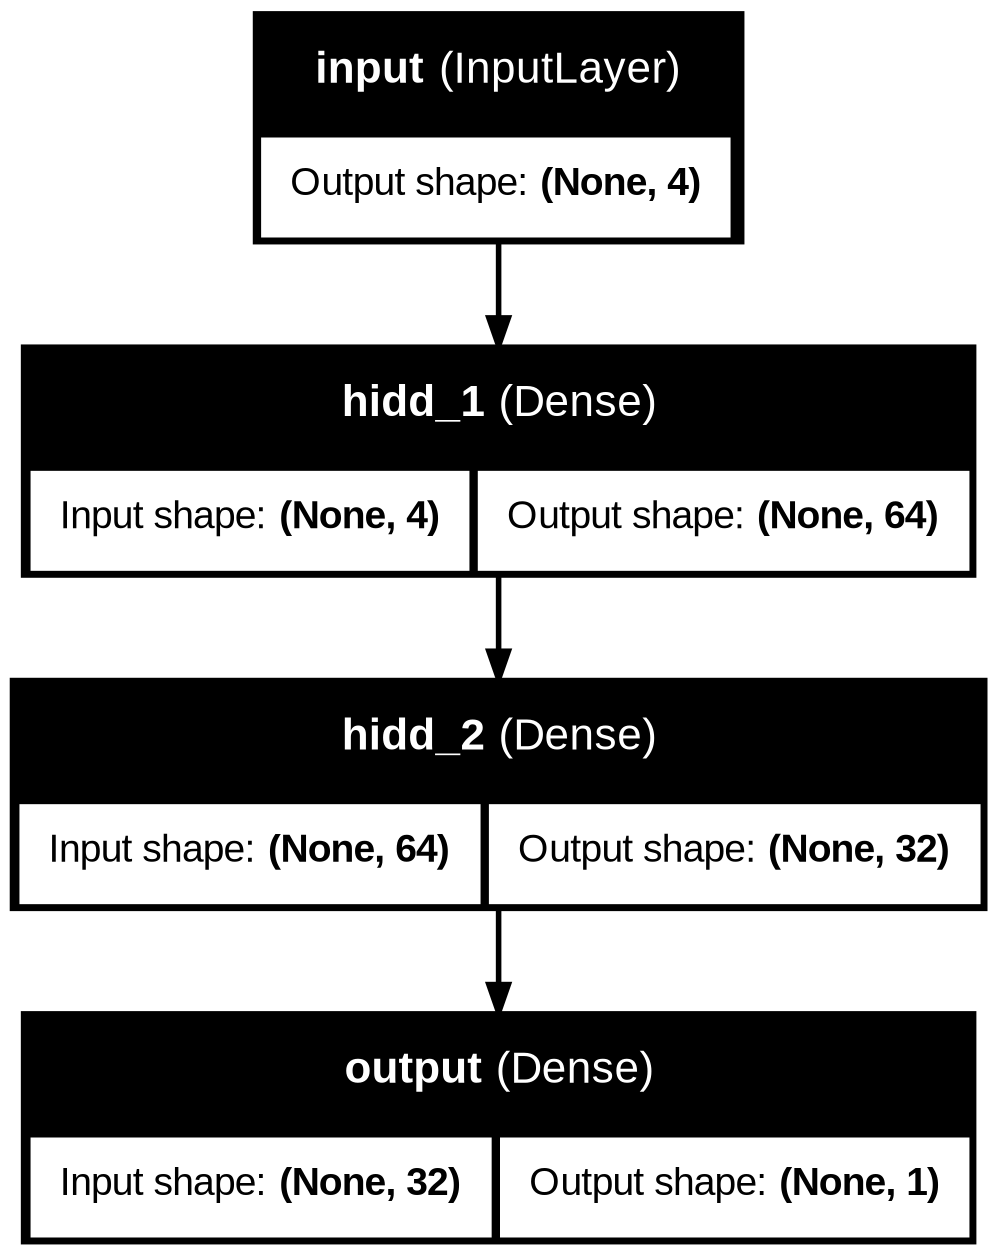

In [134]:
#@title Visualizar modelo
mostrar_modelo = True #@param {type:"boolean"}
if mostrar_modelo:
    if model is None:
        print("Modelo no disponible.")
    else:
        print("Modelo con", len(model.layers), "capas:")
        display(plot_model(model, show_layer_names=True, show_shapes=True))

In [135]:
#@title Entrenar modelo

cant_epocas_entrenamiento = 250 #@param {type:"integer"}
porcentaje_datos_validacion = 15 #@param {type:"number"}

#@markdown Configuracion Early Stopping:
activar_early_stopping = True #@param {type:"boolean"}
epoca_comienza_monitorear = 15 #@param {type:"integer"}
min_cambio_considera_mejora = 0.001 #@param {type:"number"}
epocas_paciencia = 25 #@param {type:"integer"}
devolver_pesos = "Mejores" #@param ["Mejores", "Ultimos"]

# Controlar parametros
cantEpocas = max(1, cant_epocas_entrenamiento)
porcentaje_datos_validacion = min(49.9, max(0.5, porcentaje_datos_validacion))

print(f"\n> De los {len(x_train)} ejemplos de entrenamiento, "
      f"{100-porcentaje_datos_validacion:.1f}% para entrenar y "
      f"{porcentaje_datos_validacion:.1f}% para validar.")

# Configurar early stopping
callbacksList = []
if activar_early_stopping:
    early_stopping_monitor = keras.callbacks.EarlyStopping(
        monitor='val_loss',
        min_delta=min_cambio_considera_mejora,
        patience=epocas_paciencia,
        verbose=1,
        mode='min',
        restore_best_weights=(devolver_pesos == "Mejores"),
        start_from_epoch=epoca_comienza_monitorear
    )
    callbacksList = [early_stopping_monitor]
    print("> Early Stopping activado.")

# Entrenar
start_time = time.process_time()
print("\n> Comienza el entrenamiento:")

history = model.fit(
    x=x_train,
    y=y_train,
    epochs=cantEpocas,
    validation_split=porcentaje_datos_validacion/100.0,
    callbacks=callbacksList,
    verbose=1
)

duration = time.process_time() - start_time
if duration > 60:
    print(f"\n> Entrenamiento finalizado: {duration/60.0:.3f} minutos.")
else:
    print(f"\n> Entrenamiento finalizado: {duration:.3f} segundos.")

# Identificar epoca de early stopping
epoch_earlyStopping = None
if callbacksList:
    for cb in callbacksList:
        if isinstance(cb, keras.callbacks.EarlyStopping):
            if cb.restore_best_weights and cb.best_epoch > 0:
                epoch_earlyStopping = cb.best_epoch + 1
            elif cb.stopped_epoch > 0:
                epoch_earlyStopping = cb.stopped_epoch + 1


> De los 837 ejemplos de entrenamiento, 85.0% para entrenar y 15.0% para validar.
> Early Stopping activado.

> Comienza el entrenamiento:
Epoch 1/250
23/23 ━━━━━━━━━━━━━━━━━━━━ 2s 42ms/step - RootMeanSquaredError: 78.8730 - loss: 6220.9551 - val_RootMeanSquaredError: 79.2616 - val_loss: 6282.4004
Epoch 2/250
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - RootMeanSquaredError: 77.6420 - loss: 6028.2822 - val_RootMeanSquaredError: 77.5341 - val_loss: 6011.5312
Epoch 3/250
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - RootMeanSquaredError: 75.2052 - loss: 5655.8154 - val_RootMeanSquaredError: 74.1191 - val_loss: 5493.6440
Epoch 4/250
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - RootMeanSquaredError: 70.5603 - loss: 4978.7588 - val_RootMeanSquaredError: 67.8664 - val_loss: 4605.8423
Epoch 5/250
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - RootMeanSquaredError: 62.6438 - loss: 3924.2402 - val_RootMeanSquaredError: 58.0269 - val_loss: 3367.1216
Epoch 6/250
23/23 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - RootMeanSqu

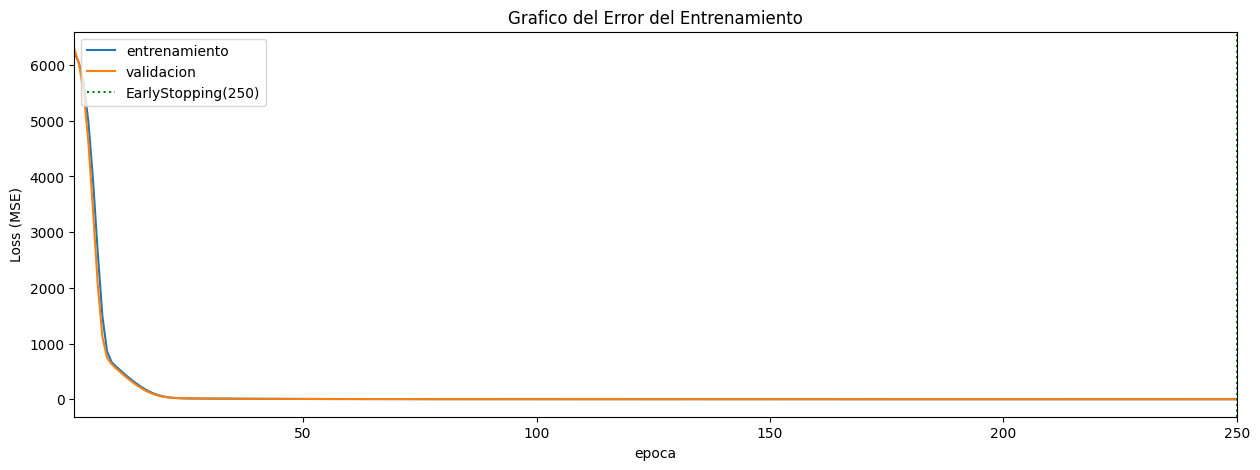

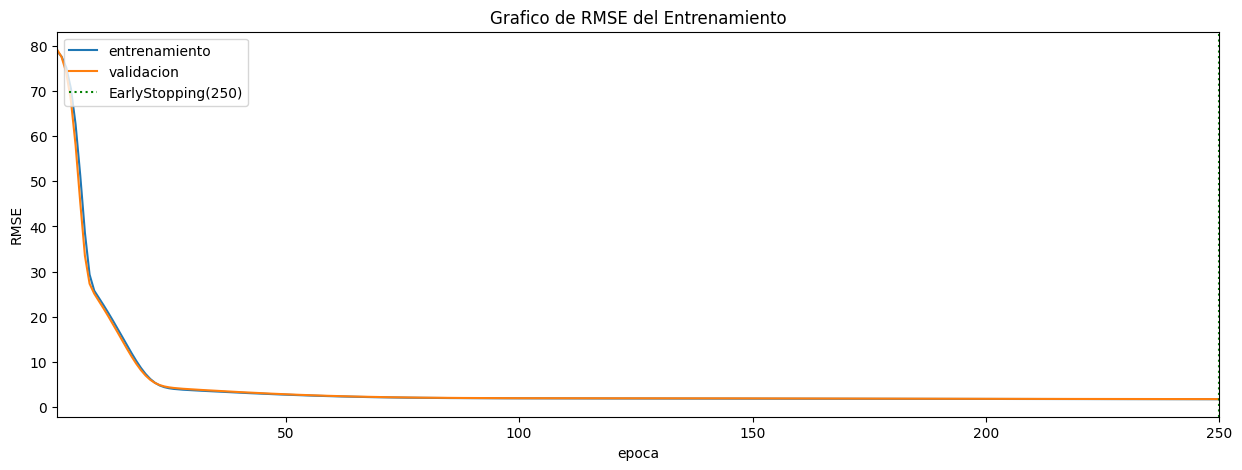

In [136]:
#@title Mostrar graficos del entrenamiento

# Grafico de LOSS
plt.figure(figsize=(15, 5))
plt.plot([None] + history.history['loss'])
plt.plot([None] + history.history['val_loss'])
legendsLabels = ['entrenamiento', 'validacion']
plt.ylabel('Loss (MSE)')
plt.xlabel('epoca')
plt.title('Grafico del Error del Entrenamiento')
if epoch_earlyStopping is not None:
    esLabel = f"EarlyStopping({epoch_earlyStopping})"
    plt.axvline(x=epoch_earlyStopping, color='g', linestyle=':', label=esLabel)
    legendsLabels.append(esLabel)
plt.legend(legendsLabels, loc='upper left')
plt.margins(x=0)
plt.show()

# Grafico de RMSE
plt.figure(figsize=(15, 5))
rmse_key = 'RootMeanSquaredError' if 'RootMeanSquaredError' in history.history else 'root_mean_squared_error'
val_rmse_key = 'val_' + rmse_key
if rmse_key in history.history:
    plt.plot([None] + history.history[rmse_key])
    if val_rmse_key in history.history:
        plt.plot([None] + history.history[val_rmse_key])
    plt.ylabel('RMSE')
    plt.xlabel('epoca')
    plt.title('Grafico de RMSE del Entrenamiento')
    if epoch_earlyStopping is not None:
        plt.axvline(x=epoch_earlyStopping, color='g', linestyle=':')
    plt.legend(legendsLabels, loc='upper left')
    plt.margins(x=0)
    plt.show()

---
## 3. Evaluacion del modelo

Se evalua con datos de entrenamiento y de prueba, mostrando:
- Error absoluto y relativo por prediccion
- Distribucion de errores (histograma)
- Metricas globales: MSE, RMSE, MAE, R2

*** Resultados con datos de Entrenamiento: ***

  Estadisticas para Error Absoluto:
    Minimo: 0.0020
    Promedio: 1.3785 +/- 1.0327
    Maximo: 5.5791


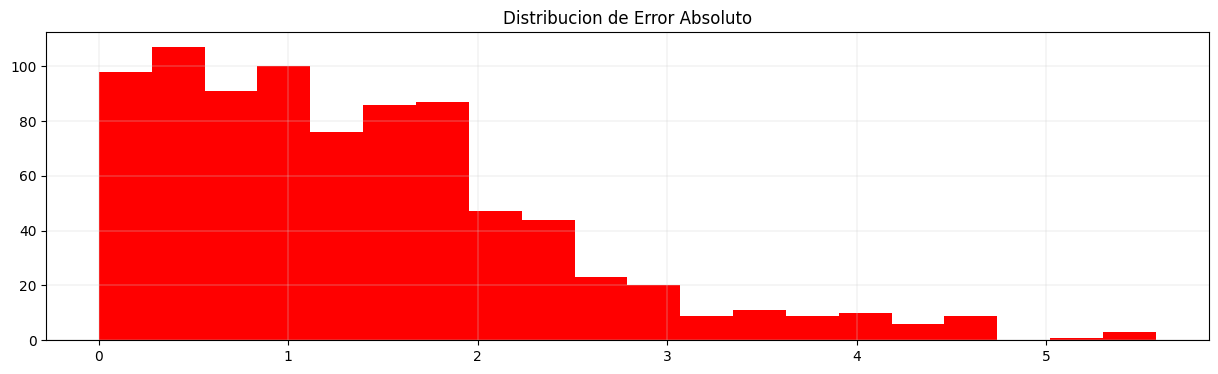


  Estadisticas para Error Relativo:
    Minimo: 0.0022
    Promedio: 1.9240 +/- 1.5637
    Maximo: 10.1539


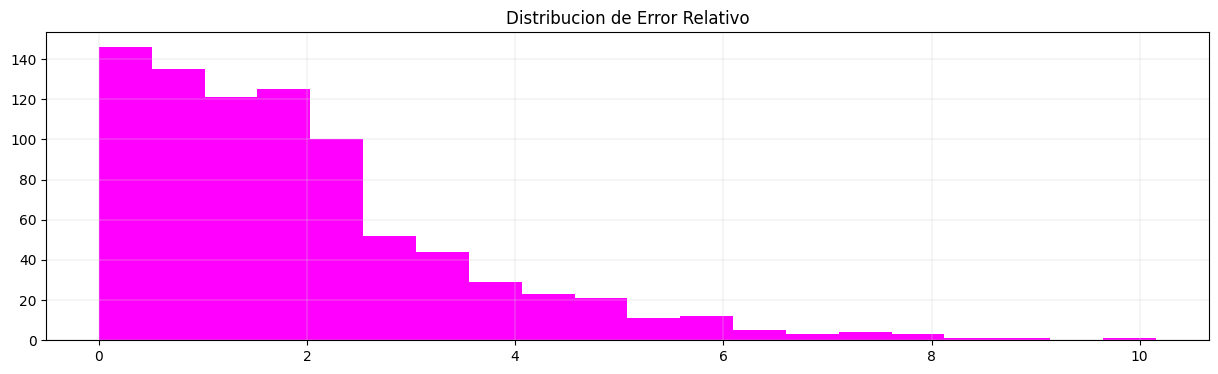


  Metricas globales:
    MSE:  2.9668
    RMSE: 1.7224
    MAE:  1.3785
    R2:   0.9922


In [137]:
#@title Evaluar con datos de entrenamiento
mostrar_detalle_entrenamiento = False #@param {type:"boolean"}
incluirDatosEntrada_detalle_entrenamiento = False #@param {type:"boolean"}

def generaResumen_Estimacion(ar, tit, b=20, c=None):
    print(f"\n  Estadisticas para {tit}:")
    print(f"    Minimo: {np.min(ar):.4f}")
    print(f"    Promedio: {np.mean(ar):.4f} +/- {np.std(ar):.4f}")
    print(f"    Maximo: {np.max(ar):.4f}")
    fig = plt.figure(figsize=(15, 4))
    plt.hist(ar, bins=b, color=c)
    plt.grid(color='lightgrey', linestyle='solid', linewidth=0.3)
    plt.title(f"Distribucion de {tit}")
    plt.show()

def analizarModelo_Estimacion(datosX, datosY, predsY, mostrarDetalle=False, inclDatosEntrada=False):
    if mostrarDetalle:
        if inclDatosEntrada:
            print(" Datos ->", end="")
        print(" Valor Real / Valor Modelo [ Error Absoluto | Error Relativo ]")
    arAbs = []
    arRel = []
    for x, r, pV in zip(datosX, datosY, predsY):
        p = pV[0] if hasattr(pV, '__len__') else pV
        if not(math.isnan(r) or math.isnan(p)):
            eAbs = abs(r - p)
            eRel = (eAbs / r * 100.0) if r != 0 else (eAbs * 100.0)
            arAbs.append(eAbs)
            arRel.append(eRel)
            if mostrarDetalle:
                if inclDatosEntrada:
                    print(f" {x}->", end="")
                print(f" R: {r:>10.4f} / M: {p:>10.4f} [ {eAbs:>10.4f} | {eRel:>10.2f}% ]")
    generaResumen_Estimacion(arAbs, "Error Absoluto", 20, "red")
    generaResumen_Estimacion(arRel, "Error Relativo", 20, "magenta")

    # Metricas globales
    y_real = np.array([r for r in datosY if not math.isnan(r)])
    y_pred = np.array([pV[0] if hasattr(pV, '__len__') else pV for pV, r in zip(predsY, datosY) if not math.isnan(r)])
    mse = mean_squared_error(y_real, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_real, y_pred)
    r2 = r2_score(y_real, y_pred)
    print(f"\n  Metricas globales:")
    print(f"    MSE:  {mse:.4f}")
    print(f"    RMSE: {rmse:.4f}")
    print(f"    MAE:  {mae:.4f}")
    print(f"    R2:   {r2:.4f}")
    return {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

def evaluarModelo(modelo, datosX, datosY, mostrarDetalle=False, inclDatosEntrada=False):
    predsY = modelo.predict(datosX, verbose=0)
    return analizarModelo_Estimacion(datosX, datosY, predsY, mostrarDetalle, inclDatosEntrada)

print("*** Resultados con datos de Entrenamiento: ***")
metricas_train = evaluarModelo(model, x_train, y_train,
                               mostrarDetalle=mostrar_detalle_entrenamiento,
                               inclDatosEntrada=incluirDatosEntrada_detalle_entrenamiento)


*** Resultados con datos de Prueba: ***

  Estadisticas para Error Absoluto:
    Minimo: 0.0127
    Promedio: 1.3613 +/- 1.0342
    Maximo: 4.6261


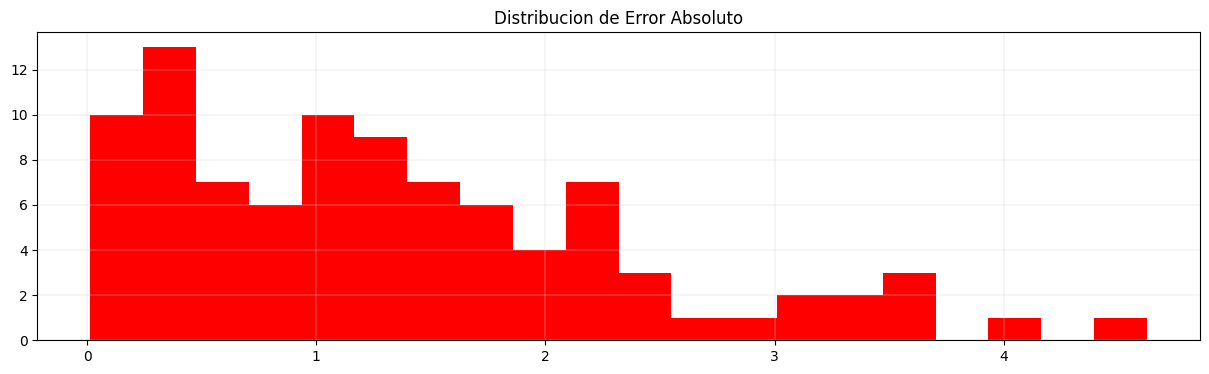


  Estadisticas para Error Relativo:
    Minimo: 0.0133
    Promedio: 1.9781 +/- 1.6444
    Maximo: 7.4526


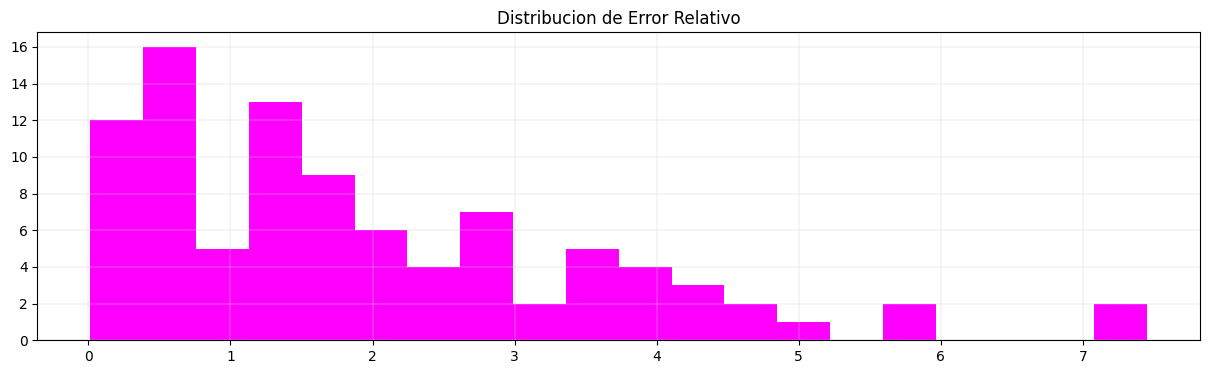


  Metricas globales:
    MSE:  2.9226
    RMSE: 1.7096
    MAE:  1.3613
    R2:   0.9933


In [138]:
#@title Evaluar con datos de prueba
mostrar_detalle_prueba = False #@param {type:"boolean"}
incluirDatosEntrada_detalle_prueba = False #@param {type:"boolean"}

print("\n*** Resultados con datos de Prueba: ***")
metricas_test = evaluarModelo(model, x_test, y_test,
                              mostrarDetalle=mostrar_detalle_prueba,
                              inclDatosEntrada=incluirDatosEntrada_detalle_prueba)

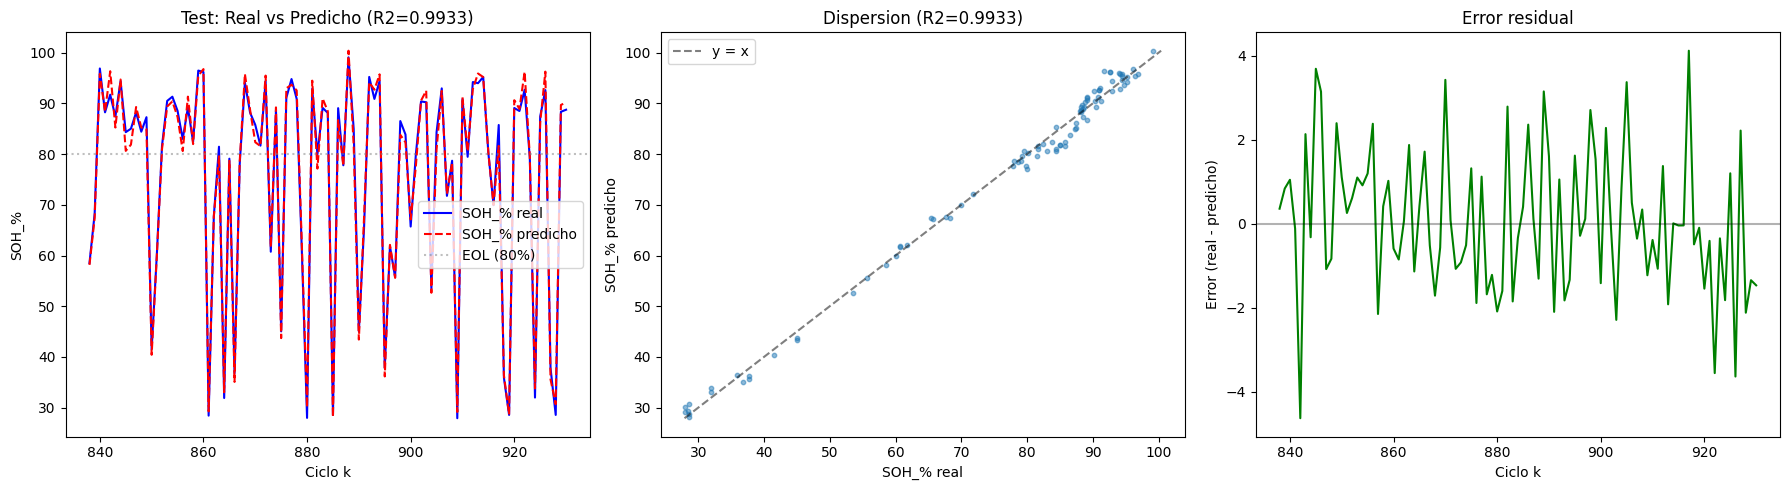

In [139]:
#@title Grafico: prediccion vs real
preds_test = model.predict(x_test, verbose=0).flatten()
preds_train = model.predict(x_train, verbose=0).flatten()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Prediccion vs real (test)
ciclos_test = range(len(x_train)+1, len(x_train)+len(x_test)+1)
axes[0].plot(ciclos_test, y_test, 'b-', label=f'{target_seleccionado} real')
axes[0].plot(ciclos_test, preds_test, 'r--', label=f'{target_seleccionado} predicho')
if target_seleccionado == 'SOH_%':
    axes[0].axhline(y=80, color='gray', linestyle=':', alpha=0.5, label='EOL (80%)')
axes[0].set_xlabel('Ciclo k')
axes[0].set_ylabel(target_seleccionado)
axes[0].set_title(f'Test: Real vs Predicho (R2={metricas_test["R2"]:.4f})')
axes[0].legend()

# Scatter
axes[1].scatter(y_test, preds_test, alpha=0.5, s=10)
lims = [min(y_test.min(), preds_test.min()), max(y_test.max(), preds_test.max())]
axes[1].plot(lims, lims, 'k--', alpha=0.5, label='y = x')
axes[1].set_xlabel(f'{target_seleccionado} real')
axes[1].set_ylabel(f'{target_seleccionado} predicho')
axes[1].set_title(f'Dispersion (R2={metricas_test["R2"]:.4f})')
axes[1].legend()

# Error residual
axes[2].plot(ciclos_test, y_test - preds_test, 'g-')
axes[2].axhline(y=0, color='k', linestyle='-', alpha=0.3)
axes[2].set_xlabel('Ciclo k')
axes[2].set_ylabel('Error (real - predicho)')
axes[2].set_title('Error residual')

plt.tight_layout()
plt.show()

---
## 4. Experimentacion de topologias

Se entrena el RNA MLP BP con distintas configuraciones de capas ocultas y neuronas para ajustar la estimacion del error.

Cada topologia se entrena con los mismos parametros (Adam, lr=0.001, early stopping) y se comparan las metricas sobre el conjunto de test.

In [140]:
#@title Experimentar con multiples topologias
#@markdown Topologias a probar (formato: 'neuronas' separadas por comas):
topologias_str = "16, 32, 64, 64,32, 128,64, 128,64,32, 32,16, 64,32,16" #@param {type:"string"}

# 3 modelos con complejidad creciente
topologias = {
    'M1': ['8'],
    'M2': ['64', '32'],
    'M3': ['128', '64', '32'],
}
epocas_por_modelo = {'M1': 50, 'M2': 300, 'M3': 400}

print(f"Modelos a experimentar: {len(topologias)}")
for tid, neurons in topologias.items():
    print(f"  {tid}: {','.join(neurons)} ({epocas_por_modelo[tid]} epocas)")

# Funcion para entrenar y evaluar una topologia
def experimentar_topologia(x_train, y_train, x_test, y_test, neuronas, epocas=200, nombre='RNA'):
    input_Lay = agregarCapaEntrada(num_inputs=x_train.shape[1])
    eachLay = input_Lay
    eachLay = agregarCapasLineales(eachLay, configCapasList=neuronas,
                                   tipo_funcion='relu', porc_capa_DropOut=0.0)
    output_Lay, metricsType, lossType = agregarCapaSalida(eachLay)
    opt = definirOpt('Adam', 0.001)
    m = Model(input_Lay, output_Lay, name=nombre)
    m.compile(optimizer=opt, loss=lossType, metrics=metricsType)

    es = keras.callbacks.EarlyStopping(monitor='val_loss', patience=20, restore_best_weights=True, verbose=0)
    m.fit(x_train, y_train, validation_split=0.15, epochs=epocas, batch_size=32, callbacks=[es], verbose=0)

    preds = m.predict(x_test, verbose=0).flatten()
    mse = mean_squared_error(y_test, preds)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, preds)
    r2 = r2_score(y_test, preds)
    return m, {'MSE': mse, 'RMSE': rmse, 'MAE': mae, 'R2': r2}

# Experimentar
resultados = {}
modelos = {}
print(f"\n=== Experimentacion para target: {target_seleccionado} ===\n")
for tid, neurons in topologias.items():
    print(f"Entrenando {tid}: {neurons} ({epocas_por_modelo[tid]} epocas) ...", end=" ")
    m, met = experimentar_topologia(x_train, y_train, x_test, y_test,
                                   neurons, epocas=epocas_por_modelo[tid], nombre=f'MLP_{tid}')
    resultados[tid] = {'neuronas': ','.join(neurons), 'epocas': epocas_por_modelo[tid], **met}
    modelos[tid] = m
    print(f"RMSE={met['RMSE']:.4f}  MAE={met['MAE']:.4f}  R2={met['R2']:.4f}")

# Tabla de resultados
df_resultados = pd.DataFrame(resultados).T
df_resultados = df_resultados[['neuronas', 'epocas', 'MSE', 'RMSE', 'MAE', 'R2']]
print("\n=== Resultados por topologia ===")
display(df_resultados)

# Mejor topologia
mejor_id = df_resultados['R2'].idxmax()
print(f"\nMejor topologia: {mejor_id} {topologias[mejor_id]} (R2={df_resultados.loc[mejor_id, 'R2']:.4f})")

Modelos a experimentar: 3
  M1: 8 (50 epocas)
  M2: 64,32 (300 epocas)
  M3: 128,64,32 (400 epocas)

=== Experimentacion para target: SOH_% ===

Entrenando M1: ['8'] (50 epocas) ... RMSE=50.0783  MAE=45.1749  R2=-4.7290
Entrenando M2: ['64', '32'] (300 epocas) ... RMSE=1.7816  MAE=1.4022  R2=0.9927
Entrenando M3: ['128', '64', '32'] (400 epocas) ... RMSE=1.1574  MAE=0.9339  R2=0.9969

=== Resultados por topologia ===


,neuronas,epocas,MSE,RMSE,MAE,R2
M1,8,50,2507.840576,50.078344,45.174889,-4.729012
M2,"64,32",300,3.173922,1.781551,1.402173,0.992749
M3,"128,64,32",400,1.339535,1.157383,0.933937,0.99694



Mejor topologia: M3 ['128', '64', '32'] (R2=0.9969)


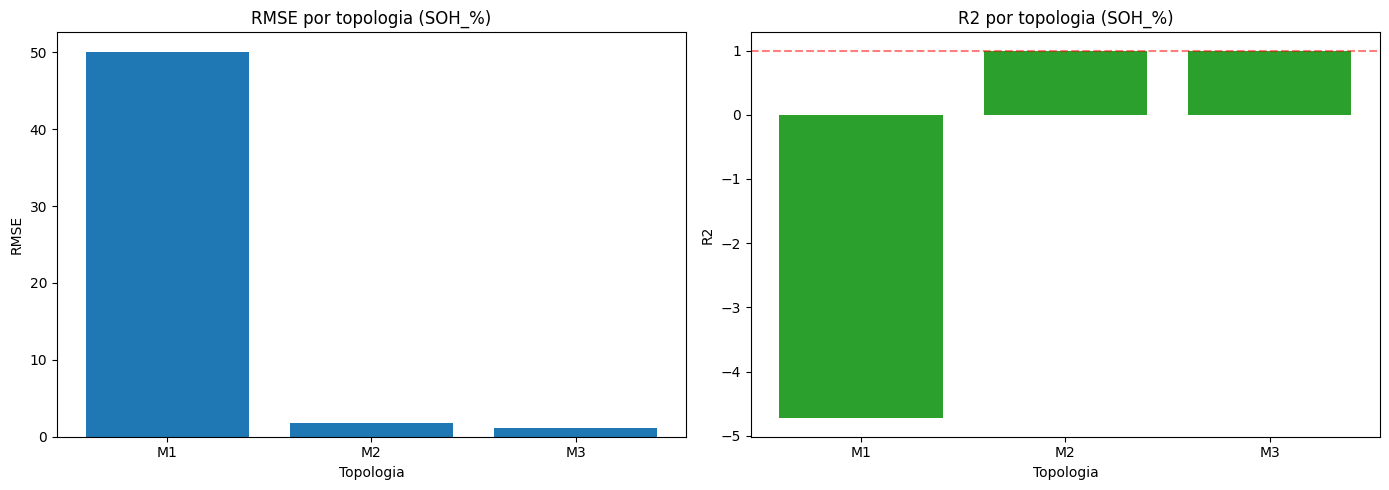

In [141]:
#@title Grafico comparativo de topologias
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(df_resultados.index, df_resultados['RMSE'], color='tab:blue')
axes[0].set_xlabel('Topologia')
axes[0].set_ylabel('RMSE')
axes[0].set_title(f'RMSE por topologia ({target_seleccionado})')

axes[1].bar(df_resultados.index, df_resultados['R2'], color='tab:green')
axes[1].axhline(y=df_resultados['R2'].max(), color='r', linestyle='--', alpha=0.5)
axes[1].set_xlabel('Topologia')
axes[1].set_ylabel('R2')
axes[1].set_title(f'R2 por topologia ({target_seleccionado})')

plt.tight_layout()
plt.show()

In [142]:
#@title Guardar modelos
PATH_MODELOS = '/content/drive/MyDrive/IA 2C 2026 G12/TP 2/Modelos/' #@param {type:"string"}

# Guardar mejor MLP
mejor_mlp = modelos[mejor_id]
mejor_mlp.save(PATH_MODELOS + f'rna_mlp_{target_seleccionado.replace("%", "")}.h5')

print(f"Modelo guardado en {PATH_MODELOS}:")
print(f"  - rna_mlp_{target_seleccionado}.h5  (MLP {mejor_id} {topologias[mejor_id]})")
print(f"\nPara cargarlo despues:")
print(f"  modelo_mlp = keras.models.load_model('{PATH_MODELOS}rna_mlp_{target_seleccionado}.h5')")

Modelo guardado en /content/drive/MyDrive/IA 2C 2026 G12/TP 2/Modelos/:
  - rna_mlp_SOH_%.h5  (MLP M3 ['128', '64', '32'])

Para cargarlo despues:
  modelo_mlp = keras.models.load_model('/content/drive/MyDrive/IA 2C 2026 G12/TP 2/Modelos/rna_mlp_SOH_%.h5')
